In [1]:
import tables as tb
import numpy  as np
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
import matplotlib        as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection
%matplotlib notebook
%matplotlib inline
### Useful parameters for plots
mpl.rcParams["figure.figsize"]          = 12,10
mpl.rcParams["font.size"]               = 20
mpl.rcParams["figure.max_open_warning"] = 100
mpl.rcParams["font.size"]               = 20
mpl.rcParams["font.weight"]             ='normal'
mpl.rcParams["axes.labelweight"] = "normal"
mpl.rcParams['axes.facecolor'] = 'w'
mpl.rcParams['figure.facecolor'] = 'w';

import invisible_cities.io.pmaps_io as pmapio
import invisible_cities.io.dst_io  as dstio

len is  1000


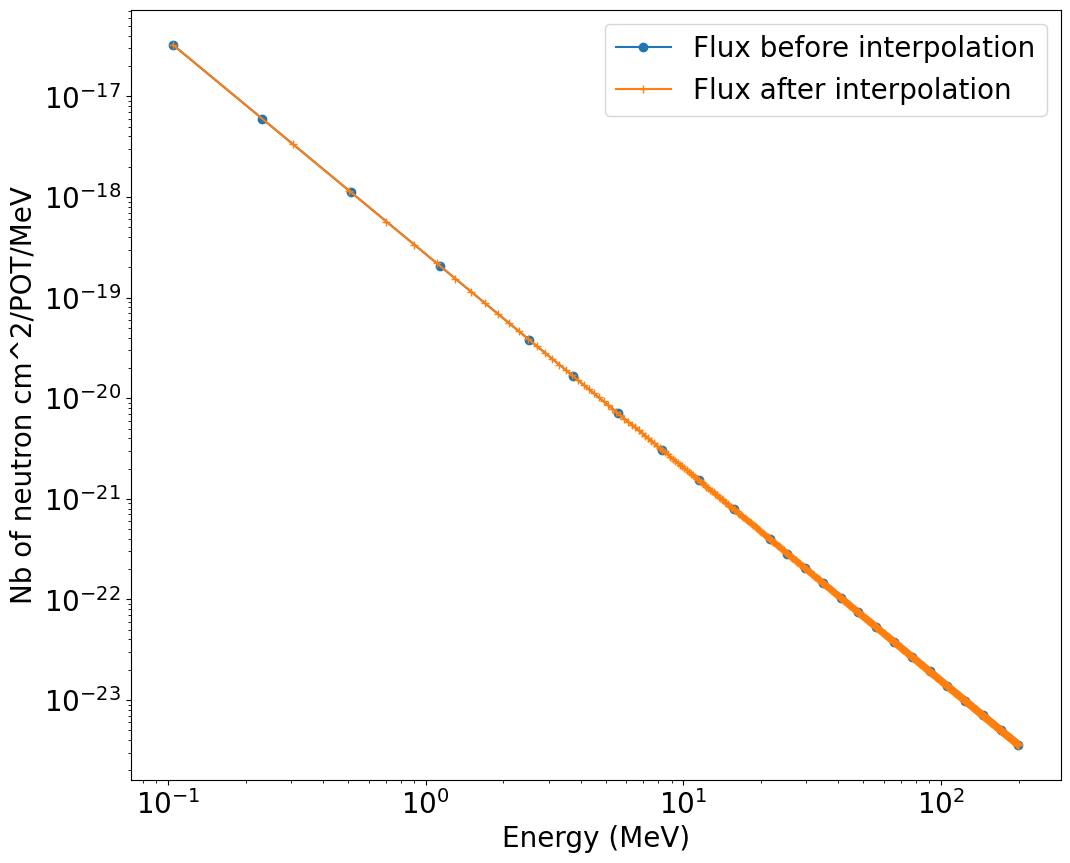

3.924832475132624e-17
before sort 1000
after sort 1000
3.924832475132624e-17
            ene          flux
0      0.104500  3.260700e-17
1      0.304345  3.378890e-18
2      0.504191  1.158394e-18
3      0.704036  5.706298e-19
4      0.903881  3.359102e-19
..          ...           ...
995  198.950619  3.615717e-24
996  199.150464  3.608027e-24
997  199.350309  3.600361e-24
998  199.550155  3.592718e-24
999  199.750000  3.585100e-24

[1000 rows x 2 columns]
            ene          norm
0      0.104500  8.307871e-01
1      0.304345  8.609005e-02
2      0.504191  2.951449e-02
3      0.704036  1.453896e-02
4      0.903881  8.558587e-03
..          ...           ...
995  198.950619  9.212412e-08
996  199.150464  9.192818e-08
997  199.350309  9.173285e-08
998  199.550155  9.153813e-08
999  199.750000  9.134403e-08

[1000 rows x 2 columns]
1.0000000000000002


In [6]:
main_path = '/home/investigator/neutron_bg/flux/'
file = 'flux_mark.txt'

df = pd.read_csv(main_path + file, delim_whitespace=True, header=None, names=['ene', 'flux'])


#to generate values in a continuous way
import itertools
#x_coord = df2['ene']
#y_coord = df2['norm']
x_coord = df['ene']
y_coord = df['flux']

x_log_store = []
y_log_store = []
#for i in range(1, len(x_coord)):
x1 = x_coord[0]
x2 = x_coord[len(x_coord) - 1]
y1 = y_coord[0]
y2 = y_coord[len(x_coord) - 1]

log_x = np.log10([x1, x2])
log_y = np.log10([y1, y2])
x_log = np.logspace(np.log10(x1), np.log10(x2), 1000) ### value to change for generating more or less points
x_lin = np.linspace(x1, x2 , 1000)
a, b = np.polyfit(log_x, log_y, 1)
y_log = 10**(a * np.log10(x_log) + b)
y_lin = 10**(a * np.log10(x_lin) + b)
x_log_store.append(x_lin)
y_log_store.append(y_lin)

    

x_log_store = list(itertools.chain.from_iterable(x_log_store))
y_log_store = list(itertools.chain.from_iterable(y_log_store))

plt.plot(x_coord, y_coord, marker='o', label='Flux before interpolation')
plt.plot(x_log_store, y_log_store, marker='+', label='Flux after interpolation')

print('len is ', len(x_log_store))
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Energy (MeV)')
plt.ylabel('Nb of neutron cm^2/POT/MeV')
plt.show()
df_store = pd.DataFrame({})
print(np.sum(y_log_store))
df_store['flux'] = y_log_store
df_store['ene'] = x_log_store
print('before sort', len(df_store))
df_store = df_store.drop_duplicates(subset='ene', keep='first')
print('after sort', len(df_store))
print(df_store['flux'].sum())

df_store['norm'] = df_store['flux']/df_store['flux'].sum()

df_store_for_integral = pd.DataFrame({})
df_store_for_integral = df_store[['ene','flux']]
print(df_store_for_integral)

df_store_final = pd.DataFrame({})
df_store_final = df_store[['ene','norm']]

print(df_store_final)
print(df_store_final['norm'].sum())

#df_store_final.to_csv(main_path + 'flux_norm.txt', sep='\t', index=False)
df_store_for_integral.to_csv(main_path + 'flux_mark_for_integral.txt', sep='\t', index=False)